# Where should the 1990 ambulances wait? — p-median location in the North Western Province

**Problem.** Choose *p* ambulance bases from a set of candidate sites so that the total
population-weighted response time to all 2,158 Grama Niladhari (GN) divisions of the
North Western Province (Kurunegala + Puttalam) is as small as possible.

**Methods compared**
1. **Exact:** Integer Linear Programming (p-median ILP, CBC branch-and-bound via PuLP)
2. **Heuristic:** Greedy-add construction, improved by **Simulated Annealing** (swap moves)
3. **Bound:** LP relaxation of the ILP

**Data.** Census of Population and Housing 2012 (Department of Census and Statistics),
GN- and DS-division centroids and populations, republished at github.com/nuuuwan/gig-data.
Travel time is modelled from distance (see Section 1).

In [1]:
import sys, json
sys.path.insert(0, "src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from ambupos import (make_instance, load_gnd, load_dsd, greedy, simulated_annealing,
                     solve_ilp, solve_lp_relaxation, evaluate)
from ambupos import data as D
pd.set_option("display.precision", 3)

## 1. Data

In [2]:
gnd, dsd = load_gnd(), load_dsd()
print(f"GN divisions: {len(gnd):,}   DS divisions: {len(dsd)}   population: {gnd.population.sum():,}")
gnd.groupby("district").population.agg(["count", "sum", "mean", "min", "max"])

GN divisions: 2,158   DS divisions: 46   population: 2,379,683


,count,sum,mean,min,max
district,,,,,
Kurunegala,1610,1617287,1004.526,161,4326
Puttalam,548,762396,1391.234,113,14017


In [3]:
gnd.head()

,id,name,district,dsd_id,lat,lon,population
0,LK-6103005,Jayanthipura,Kurunegala,LK-6103,8.179,80.113,819
1,LK-6103010,Bambare,Kurunegala,LK-6103,8.174,80.136,1094
2,LK-6103015,Sandagala Palatha,Kurunegala,LK-6103,8.162,80.110,1003
3,LK-6103020,Perakumpura,Kurunegala,LK-6103,8.160,80.136,1422
4,LK-6103025,Solepura,Kurunegala,LK-6103,8.155,80.153,1149


**Travel-time assumption.** `t_ij = haversine_km(i, j) × CIRCUITY / SPEED × 60` minutes.
Circuity factor and average speed:

In [4]:
print("CIRCUITY =", D.CIRCUITY, "  SPEED_KMH =", D.SPEED_KMH)

CIRCUITY = 1.4   SPEED_KMH = 40.0


## 2. Mathematical formulation (p-median)

| Symbol | Meaning |
|---|---|
| $I$ | demand points (GN divisions), $J$ candidate base sites |
| $w_i$ | population of GN division $i$ |
| $t_{ij}$ | travel time (min) from site $j$ to GN division $i$ |
| $p$ | number of bases to open |
| $y_j\in\{0,1\}$ | 1 if a base is opened at site $j$ |
| $x_{ij}\in[0,1]$ | 1 if GN division $i$ is served from site $j$ |

$$\min \sum_{i\in I}\sum_{j\in J} w_i\, t_{ij}\, x_{ij}$$
subject to
$$\sum_{j} x_{ij}=1\;\;\forall i,\qquad x_{ij}\le y_j\;\;\forall i,j,\qquad \sum_j y_j = p,\qquad y_j\in\{0,1\}.$$

## 3. Quick live run — Puttalam district, 16 DS centres, p = 4

In [5]:
inst = make_instance(p=4, district="Puttalam")
g  = greedy(inst)
sa = simulated_annealing(inst, g["open"], seed=0)
ilp = solve_ilp(inst, time_limit=60)
lp  = solve_lp_relaxation(inst)
rows = []
for name, res in [("Greedy", g), ("SA", sa), ("ILP", ilp)]:
    e = evaluate(inst, res["open"])
    rows.append({"method": name, "runtime_s": res["runtime"], **e,
                 "bases": ", ".join(inst.sites.name[res["open"]])})
out = pd.DataFrame(rows)
print("LP lower bound on average time:", round(lp["lp_bound"] / inst.w.sum(), 3), "min")
out

LP lower bound on average time: 21.457 min


,method,runtime_s,feasible,objective,avg_time,max_time,cover_15,cover_30,bases
0,Greedy,1.829e-04,True,1.658e+07,21.741,90.820,0.330,0.795,"Kalpitiya, Puttalam, Arachchikattuwa, Nattandiya"
1,SA,2.817e-01,True,1.636e+07,21.457,110.306,0.392,0.785,"Puttalam, Mahakumbukkadawala, Chilaw, Wennappuwa"
2,ILP,8.297e-01,True,1.636e+07,21.457,110.306,0.392,0.785,"Puttalam, Mahakumbukkadawala, Chilaw, Wennappuwa"


## 4. Experiment results
Produced by `python experiments.py` (≈30–40 min) then `python plots.py`.

### E1 — Realistic case (candidate bases = DS-division centres)

In [6]:
e1 = pd.read_csv("results/e1_realistic.csv")
lpb = pd.read_csv("results/e1_lp_bounds.csv")
t1 = (e1.groupby(["instance", "method"])
        .agg(avg_time=("avg_time", "mean"), best_avg=("avg_time", "min"),
             max_time=("max_time", "mean"), cover_15=("cover_15", "mean"),
             cover_30=("cover_30", "mean"), runtime_s=("runtime", "mean"))
        .reset_index())
t1

,instance,method,avg_time,best_avg,max_time,cover_15,cover_30,runtime_s
0,Kurunegala_dsd_p7,Greedy,21.593,21.593,68.325,0.289,0.801,7.356e-04
1,Kurunegala_dsd_p7,ILP,21.030,21.030,50.510,0.291,0.812,8.213e+00
2,Kurunegala_dsd_p7,SA,21.043,21.030,51.236,0.291,0.811,2.874e-01
3,NWP_dsd_p10,Greedy,22.472,22.472,110.306,0.293,0.762,1.748e-03
4,NWP_dsd_p10,ILP,21.325,21.325,110.306,0.315,0.804,3.407e+01
5,NWP_dsd_p10,SA,21.333,21.325,110.306,0.315,0.803,3.672e-01
6,Puttalam_dsd_p4,Greedy,21.741,21.741,90.820,0.330,0.795,1.500e-04
7,Puttalam_dsd_p4,ILP,21.457,21.457,110.306,0.392,0.785,5.991e-01
8,Puttalam_dsd_p4,SA,21.457,21.457,110.306,0.392,0.785,2.545e-01


In [7]:
W = {i: make_instance(p=1, district=d).w.sum() for i, d in
     [("Puttalam_dsd_p4", "Puttalam"), ("Kurunegala_dsd_p7", "Kurunegala"), ("NWP_dsd_p10", None)]}
lpb["lp_avg_time"] = [b / W[i] for i, b in zip(lpb.instance, lpb.lp_bound)]
lpb

,instance,lp_bound,lp_runtime,lp_avg_time
0,Puttalam_dsd_p4,1.636e+07,0.490,21.457
1,Kurunegala_dsd_p7,3.401e+07,7.552,21.030
2,NWP_dsd_p10,5.075e+07,20.336,21.325


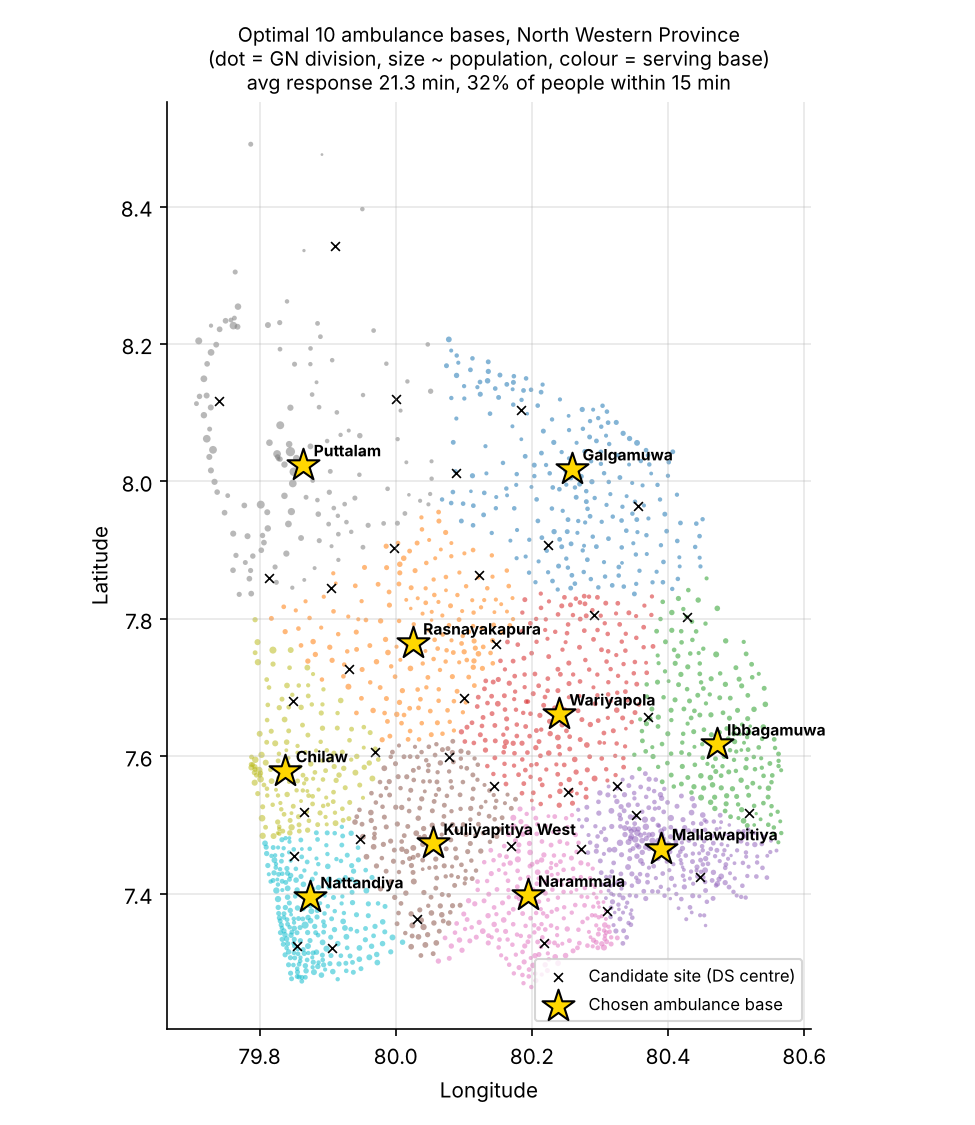

In [8]:
display(Image("figures/fig1_map_optimal_bases.png"))

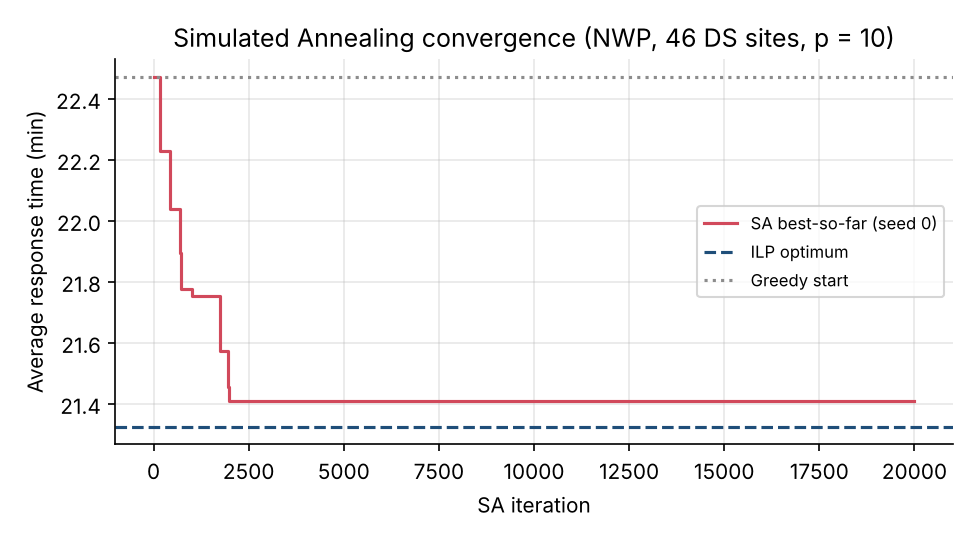

In [9]:
display(Image("figures/fig5_sa_convergence.png"))

### E2 — Scalability (whole province, |J| = 25 … 2,158 candidate GN centres, p = 10)

In [10]:
e2 = pd.read_csv("results/e2_scalability.csv")
best = e2.groupby("J").objective.min()
e2["gap_%"] = 100 * (e2.objective / e2.J.map(best) - 1)
(e2.groupby(["J", "method"])
   .agg(runtime_s=("runtime", "mean"), gap_mean=("gap_%", "mean"), gap_max=("gap_%", "max"),
        proven_opt=("optimal", "first"))
   .reset_index())

,J,method,runtime_s,gap_mean,gap_max,proven_opt
0,25,Greedy,0.001,1.693,1.693,None
1,25,ILP,14.156,0.000,0.000,True
2,25,SA,0.555,0.000,0.000,None
3,50,Greedy,0.002,3.001,3.001,None
4,50,ILP,64.171,0.000,0.000,True
5,50,SA,0.663,0.000,0.000,None
6,100,Greedy,0.008,6.427,6.427,None
7,100,ILP,317.387,0.000,0.000,False
8,100,SA,0.683,0.000,0.000,None
9,200,Greedy,0.010,7.051,7.051,None


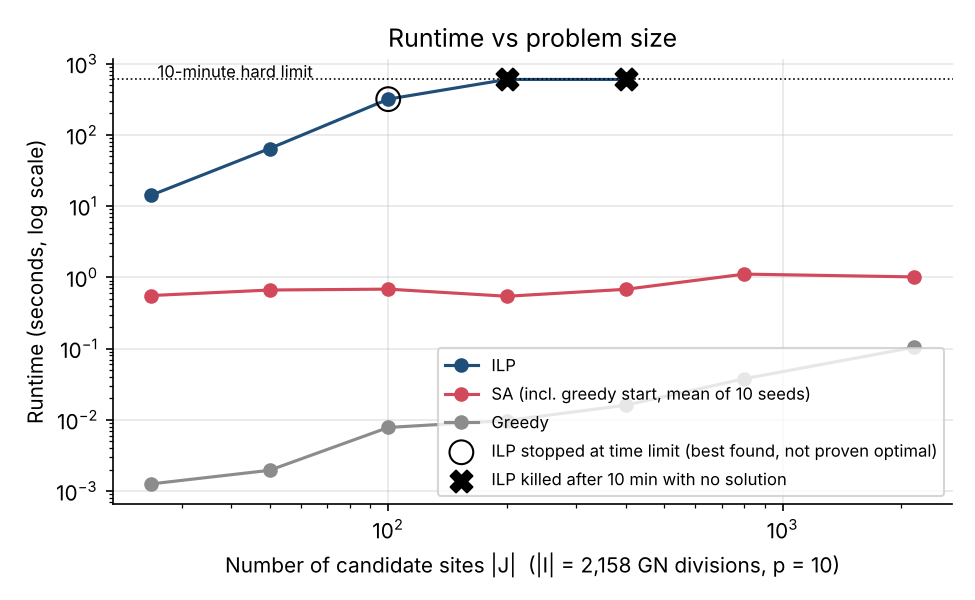

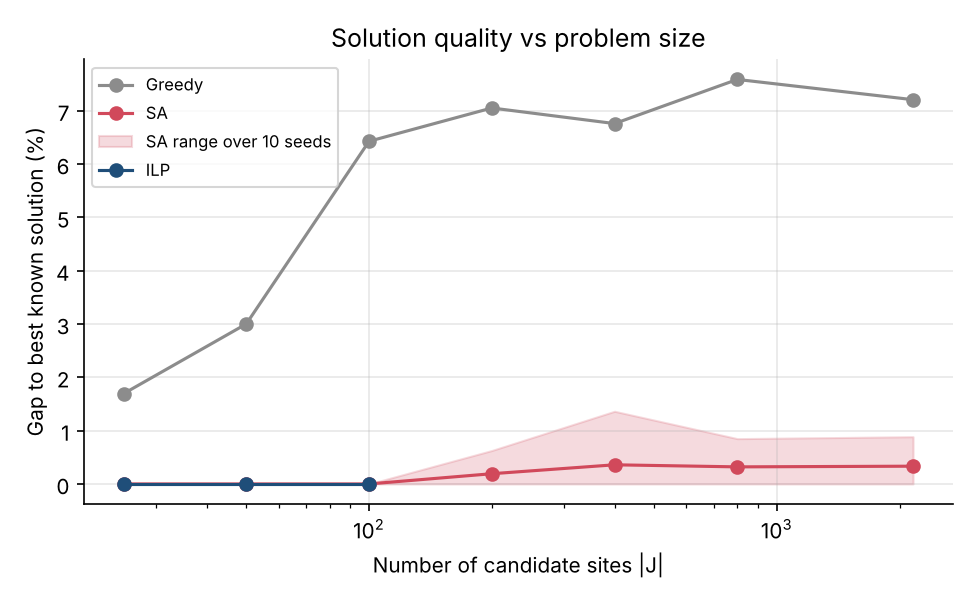

In [11]:
display(Image("figures/fig2_runtime_scalability.png"))
display(Image("figures/fig3_quality_gap.png"))

### E3 — Policy trade-off: how many bases?

In [12]:
e3 = pd.read_csv("results/e3_tradeoff.csv")
e3[e3.method == "ILP"][["p", "avg_time", "max_time", "cover_15", "cover_30", "runtime", "optimal"]]

,p,avg_time,max_time,cover_15,cover_30,runtime,optimal
6,4,34.435,110.306,0.131,0.377,70.369,True
13,6,27.863,110.306,0.212,0.584,54.650,True
20,8,23.859,110.306,0.260,0.696,41.565,True
27,10,21.325,110.306,0.315,0.804,33.076,True
34,12,19.633,90.820,0.342,0.866,20.894,True
41,15,17.579,90.820,0.398,0.923,53.073,True
48,20,15.113,90.820,0.544,0.951,13.495,True


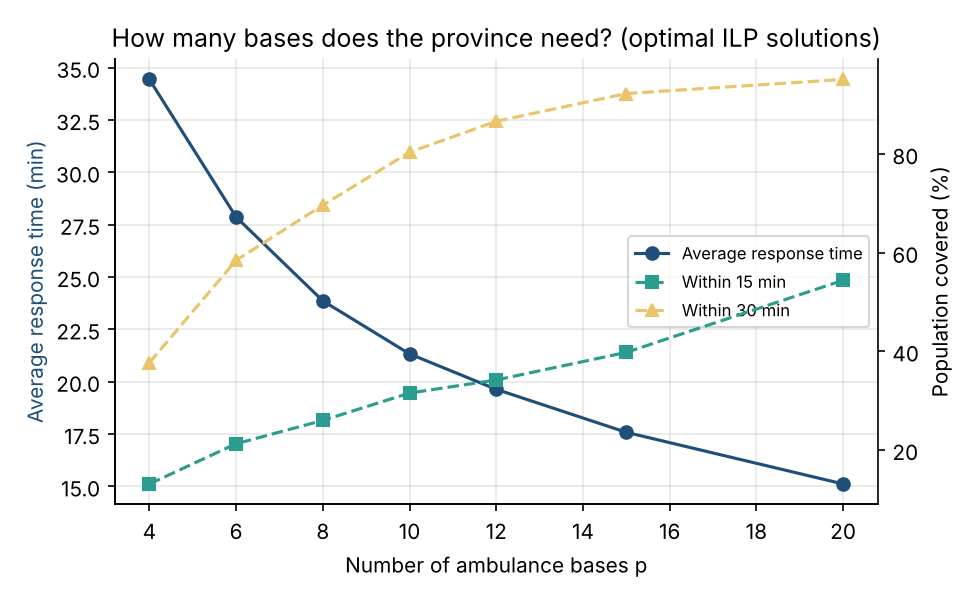

In [13]:
display(Image("figures/fig4_bases_tradeoff.png"))

## 5. Notes for the discussion
* Fill in your own interpretation here (keep it in your own words for Turnitin).